# 03 - Model Evaluation (Person 3)

**Task.** Predict whether a diabetic inpatient is readmitted within 30 days (`target = 1`).
**Final model under evaluation.** Tuned CatBoost, decision threshold chosen on a patient-grouped validation split.

This notebook only *reads* the saved predictions (`outputs/figures/test_predictions.csv`), so it never touches the
training pipeline and cannot leak test information back into modeling. Every table is written to
`outputs/evaluation/tables/` and every figure to `outputs/evaluation/figures/`.

| Section | Question answered |
|---|---|
| 1 | How good is the final model, with uncertainty? |
| 2 | Why these metrics (accuracy trap) |
| 3 | Is it significantly better than the other models? (same test rows, paired tests) |
| 4 | Which threshold should a hospital use? (cost-sensitive analysis, decision curve) |
| 5 | Who should the hospital call first? (Recall@Top-k, gain / lift) |
| 6 | What do missed readmissions and false alarms look like? (error analysis) |
| 7 | Is the model calibrated, and does it work across subgroups? |
| 8 | How do we compare with published / public baselines? |

In [2]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# locate repo root (works whether VS Code starts the kernel in notebooks/ or in the repo root)
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import evaluation as ev
from compare_models import add_advanced_features, run as run_refit

FIG = ROOT / "outputs" / "evaluation" / "figures"; TAB = ROOT / "outputs" / "evaluation" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
N_BOOT, SEED = 1000, 42

pred = pd.read_csv(ROOT / "outputs/figures/test_predictions.csv")
test = pd.read_csv(ROOT / "data/test_clean.csv")
meta = json.load(open(ROOT / "outputs/figures/best_params.json"))
THR = meta["threshold"]
y, p = pred["y_true"].to_numpy(), pred["probability"].to_numpy()

# integrity checks: predictions must be row-aligned with the test features
assert len(pred) == len(test), "row count mismatch"
assert (test["target"].to_numpy() == y).all(), "predictions are not aligned with test_clean.csv"

# Optional: patient ids of the test rows -> cluster bootstrap (see README note). Not required.
gfile = ROOT / "data" / "test_patient_groups.csv"
GROUPS = pd.read_csv(gfile)["patient_nbr"].to_numpy() if gfile.exists() else None
print(f"Test encounters: {len(y):,} | positives: {y.sum():,} ({y.mean():.2%}) | threshold: {THR:.4f}")
print("Bootstrap type :", "cluster (by patient)" if GROUPS is not None else "encounter-level (no test patient ids found)")

Test encounters: 19,802 | positives: 2,216 (11.19%) | threshold: 0.1273
Bootstrap type : encounter-level (no test patient ids found)


## 1. Headline performance of the final model

All intervals are 95% percentile bootstrap CIs (1,000 resamples). The ROC-AUC interval additionally comes from DeLong's method.

In [3]:
ci = ev.bootstrap_ci(y, p, THR, metrics=["ROC-AUC", "AP (PR-AUC)", "Precision", "Recall", "Specificity", "F1"],
                     n_boot=N_BOOT, groups=GROUPS, seed=SEED)
ci["Estimate [95% CI]"] = ci.apply(ev.fmt_ci, axis=1)
auc, lo, hi = ev.delong_auc_ci(y, p)
tm = ev.threshold_metrics(y, p, THR)
display(ci[["Metric", "Estimate [95% CI]"]].set_index("Metric"))
print(f"DeLong ROC-AUC = {auc:.3f} (95% CI {lo:.3f}-{hi:.3f})")
print(f"Confusion counts at threshold {THR:.3f}: TP={tm['TP']}, FP={tm['FP']}, FN={tm['FN']}, TN={tm['TN']}")
print(f"MCC = {tm['MCC']:.3f} | Balanced accuracy = {tm['Balanced Acc']:.3f} | NPV = {tm['NPV']:.3f} | Flagged = {tm['Flagged %']:.1f}% of patients")
ci.to_csv(TAB / "01_headline_metrics_ci.csv", index=False)

,Estimate [95% CI]
Metric,
ROC-AUC,"0.676 [0.664, 0.688]"
AP (PR-AUC),"0.243 [0.229, 0.261]"
Precision,"0.197 [0.187, 0.208]"
Recall,"0.508 [0.488, 0.528]"
Specificity,"0.739 [0.733, 0.745]"
F1,"0.284 [0.272, 0.297]"


DeLong ROC-AUC = 0.676 (95% CI 0.664-0.688)
Confusion counts at threshold 0.127: TP=1125, FP=4586, FN=1091, TN=13000
MCC = 0.172 | Balanced accuracy = 0.623 | NPV = 0.923 | Flagged = 28.8% of patients


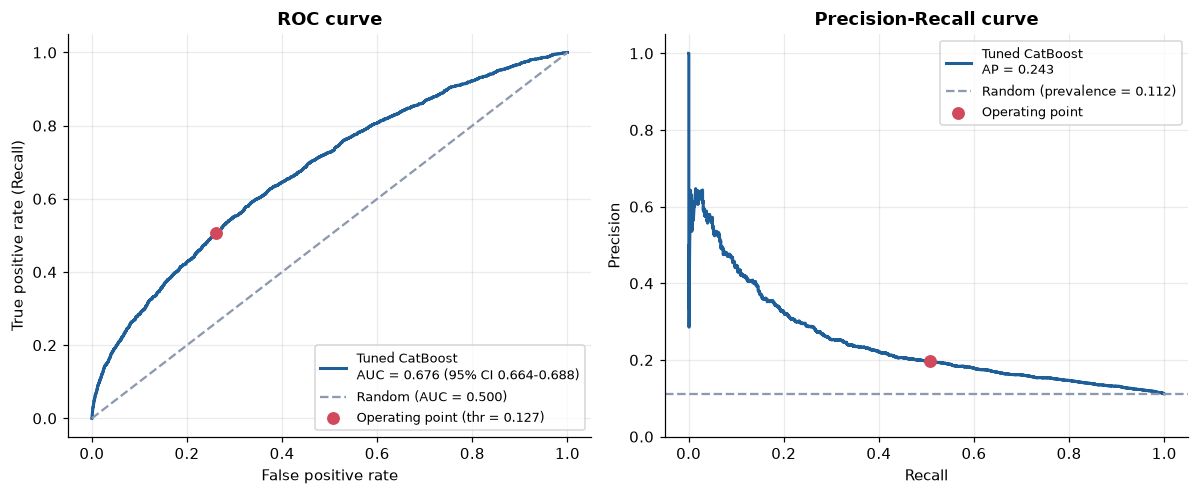

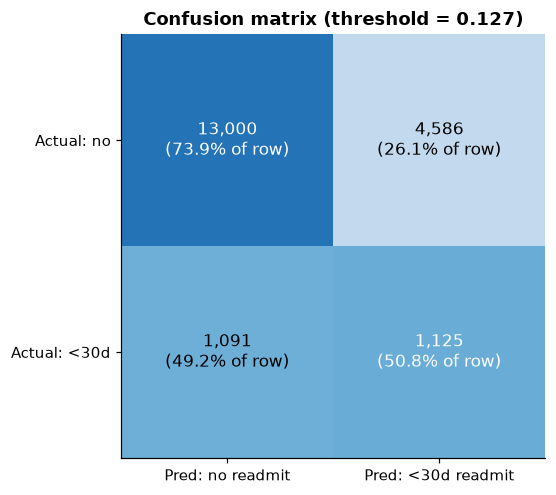

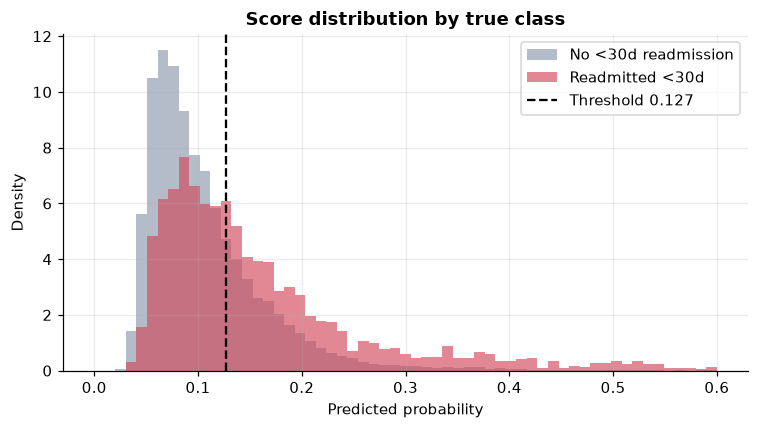

In [4]:
ev.plot_roc_pr(y, p, THR, FIG / "01_roc_pr.png"); plt.show()
ev.plot_confusion(y, p, THR, FIG / "01_confusion_matrix.png"); plt.show()
ev.plot_score_distribution(y, p, THR, FIG / "01_score_distribution.png"); plt.show()

## 2. Why accuracy is the wrong headline metric

With 11% positives, a model that never flags anyone is 89% accurate and useless. Hospitals care about
**catching readmissions (Recall)** without drowning staff in false alarms **(Precision)**, and about the *ranking* quality that is
independent of any threshold (**ROC-AUC, Average Precision**). Average Precision is the main selection metric because
its random-classifier value equals the prevalence, so its lift over chance is easy to interpret.

In [5]:
prev = y.mean()
ref = pd.DataFrame([
    {"Classifier": "Flag nobody (majority class)",   "Accuracy": 1 - prev, "Recall": 0.0, "Precision": np.nan, "F1": 0.0, "AP": prev, "ROC-AUC": 0.5},
    {"Classifier": "Flag everybody",                 "Accuracy": prev,     "Recall": 1.0, "Precision": prev,   "F1": 2*prev/(1+prev), "AP": prev, "ROC-AUC": 0.5},
    {"Classifier": "Tuned CatBoost (final model)",   "Accuracy": tm["Accuracy"], "Recall": tm["Recall"], "Precision": tm["Precision"],
     "F1": tm["F1"], "AP": ev.ranking_metrics(y, p)["AP (PR-AUC)"], "ROC-AUC": auc},
]).set_index("Classifier")
display(ref.round(3)); ref.to_csv(TAB / "02_naive_reference.csv")
r = ev.ranking_metrics(y, p)
print(f"AP is {r['AP / prevalence']:.2f}x the random baseline ({prev:.3f}).")

,Accuracy,Recall,Precision,F1,AP,ROC-AUC
Classifier,,,,,,
Flag nobody (majority class),0.888,0.000,NaN,0.000,0.112,0.500
Flag everybody,0.112,1.000,0.112,0.201,0.112,0.500
Tuned CatBoost (final model),0.713,0.508,0.197,0.284,0.243,0.676


AP is 2.17x the random baseline (0.112).


## 3. Model comparison on the *same* test rows + statistical testing

**Protocol.** Every candidate is re-fit with the identical procedure used for the final model (`src/compare_models.py`):
fit on a patient-grouped 80% of train -> choose the F1-optimal threshold on the remaining 20% -> refit on all of train -> score the test set.
Hence each model is judged at *its own* validation-selected threshold, and no test information is used for any choice.

**Tests** (all on the shared test set, paired by encounter):
DeLong for ROC-AUC differences; paired bootstrap for AP and F1 differences; exact McNemar for the decisions at each model's threshold.
Holm correction is applied across the 8 comparisons. McNemar is reported three ways: on all decisions, on actual positives only (= a test of the *recall* difference)
and on actual negatives only (= a test of the *specificity* difference). The "all" version is dominated by the 89% negatives and mostly reflects
different operating points, so interpret the recall / specificity versions rather than the "all" one.

*Why not a t-test on CV folds?* The team's CV uses only 3 folds, so the Nadeau-Bengio corrected t-test has 2 degrees of freedom and almost no power
(a Wilcoxon test on 3 folds cannot even reach p < 0.25). `ev.corrected_resampled_ttest` is provided if you later run repeated CV.

In [6]:
mp = run_refit(ROOT)                                    # uses the cached file if it exists
THR_M = json.load(open(ROOT / "outputs/evaluation/model_thresholds.json"))
assert (mp["y_true"].to_numpy() == y).all()
print(f"Sanity check - re-fit Tuned CatBoost vs team's saved predictions: max |diff| = {np.abs(mp['Tuned CatBoost'] - p).max():.2e}")

proba = {c: mp[c].to_numpy() for c in mp.columns if c != "y_true"}
proba["Tuned CatBoost"] = p                              # canonical predictions from the modeling notebook
thr_m = dict(THR_M); thr_m["Tuned CatBoost"] = THR

[cache] /Users/vianhbui/Downloads/diabetes-readmission-prediction/outputs/evaluation/model_predictions.csv exists - skipping refit (use --force to recompute)
Sanity check - re-fit Tuned CatBoost vs team's saved predictions: max |diff| = 0.00e+00


,Threshold,ROC-AUC,AP (PR-AUC),Recall,Precision,F1
Model,,,,,,
Tuned CatBoost,0.127313,"0.676 [0.663, 0.689]","0.243 [0.229, 0.261]","0.508 [0.489, 0.529]","0.197 [0.187, 0.207]","0.284 [0.272, 0.297]"
CatBoost,0.136518,"0.675 [0.662, 0.688]","0.242 [0.227, 0.261]","0.453 [0.434, 0.472]","0.204 [0.192, 0.216]","0.282 [0.267, 0.295]"
CatBoost + Class Weight,0.535537,"0.673 [0.661, 0.686]","0.232 [0.218, 0.250]","0.488 [0.468, 0.509]","0.199 [0.188, 0.209]","0.282 [0.269, 0.295]"
Random Forest,0.133030,"0.667 [0.654, 0.680]","0.223 [0.209, 0.240]","0.474 [0.454, 0.496]","0.197 [0.186, 0.207]","0.278 [0.264, 0.291]"
Logistic Regression,0.126532,"0.667 [0.653, 0.679]","0.220 [0.207, 0.237]","0.497 [0.476, 0.518]","0.194 [0.183, 0.205]","0.279 [0.266, 0.292]"
Logistic Regression + Class Weight,0.537438,"0.668 [0.654, 0.680]","0.219 [0.206, 0.237]","0.481 [0.461, 0.502]","0.196 [0.186, 0.208]","0.279 [0.266, 0.293]"
Random Forest + Class Weight,0.525637,"0.665 [0.652, 0.678]","0.214 [0.201, 0.231]","0.445 [0.424, 0.465]","0.202 [0.191, 0.213]","0.278 [0.264, 0.291]"
Decision Tree + Class Weight,0.617392,"0.646 [0.633, 0.660]","0.203 [0.191, 0.219]","0.250 [0.232, 0.270]","0.233 [0.217, 0.251]","0.241 [0.226, 0.259]"
Decision Tree,0.135135,"0.647 [0.635, 0.660]","0.203 [0.191, 0.218]","0.440 [0.421, 0.460]","0.189 [0.179, 0.199]","0.264 [0.252, 0.277]"


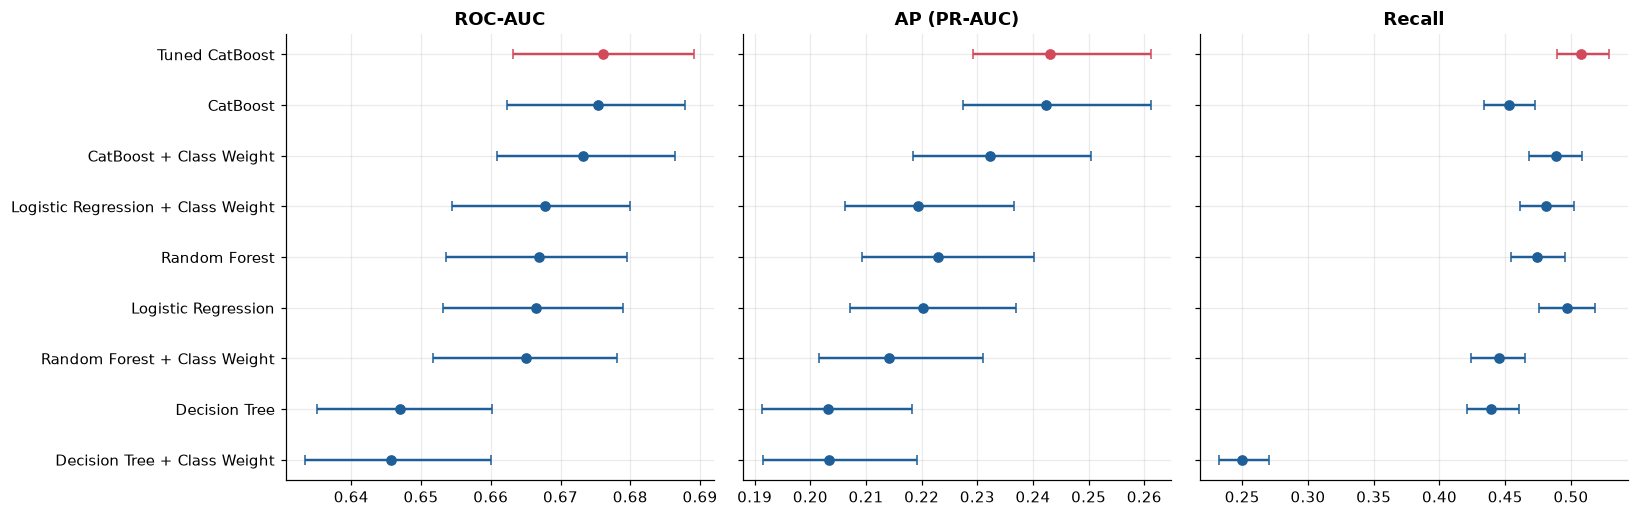

In [7]:
rows = []
for name, pr in proba.items():
    c = ev.bootstrap_ci(y, pr, thr_m[name], metrics=["ROC-AUC", "AP (PR-AUC)", "Recall", "Precision", "F1"], n_boot=500, groups=GROUPS, seed=SEED)
    d = {"Model": name, "Threshold": thr_m[name]}
    for _, r_ in c.iterrows():
        d[r_["Metric"]] = r_["Estimate"]; d[r_["Metric"] + " low"] = r_["CI low"]; d[r_["Metric"] + " high"] = r_["CI high"]
    rows.append(d)
cmp_tbl = pd.DataFrame(rows).sort_values("AP (PR-AUC)", ascending=False).reset_index(drop=True)

show = cmp_tbl[["Model", "Threshold"]].copy()
for m in ["ROC-AUC", "AP (PR-AUC)", "Recall", "Precision", "F1"]:
    show[m] = [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(cmp_tbl[m], cmp_tbl[m + " low"], cmp_tbl[m + " high"])]
display(show.set_index("Model")); cmp_tbl.to_csv(TAB / "03_model_comparison_test.csv", index=False)
ev.plot_model_comparison(cmp_tbl, ["ROC-AUC", "AP (PR-AUC)", "Recall"], FIG / "03_model_comparison.png", highlight="Tuned CatBoost"); plt.show()

In [8]:
# 2,000 paired bootstrap resamples (takes a few minutes; lower to 500 for a quick draft)
pw = ev.pairwise_comparison(y, proba, thr_m, reference="Tuned CatBoost", n_boot=2000, groups=GROUPS)
fmt = pw.copy()
for c in [c for c in fmt.columns if c.startswith("p ")]:
    fmt[c] = fmt[c].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
display(fmt[["Model", "ΔAUC", "ΔAUC 95% CI", "p DeLong (Holm)", "ΔAP", "ΔAP 95% CI", "p AP boot (Holm)", "ΔF1", "p F1 boot (Holm)",
             "p McNemar recall (Holm)", "p McNemar spec (Holm)"]].set_index("Model").round(4))
pw.to_csv(TAB / "03_pairwise_tests_vs_tuned_catboost.csv", index=False)

,ΔAUC,ΔAUC 95% CI,p DeLong (Holm),ΔAP,ΔAP 95% CI,p AP boot (Holm),ΔF1,p F1 boot (Holm),p McNemar recall (Holm),p McNemar spec (Holm)
Model,,,,,,,,,,
Logistic Regression,0.0096,"[+0.0043, +0.0149]",0.002,0.0227,"[+0.0153, +0.0305]",0.008,0.0052,0.672,0.165,0.920
Decision Tree,0.0291,"[+0.0215, +0.0367]",<0.001,0.0399,"[+0.0305, +0.0509]",0.008,0.0194,0.014,<0.001,<0.001
Random Forest,0.0092,"[+0.0058, +0.0126]",<0.001,0.0201,"[+0.0134, +0.0271]",0.008,0.0059,0.384,<0.001,<0.001
CatBoost,0.0008,"[-0.0013, +0.0029]",0.463,0.0006,"[-0.0029, +0.0043]",0.682,0.0022,0.912,<0.001,<0.001
Logistic Regression + Class Weight,0.0084,"[+0.0032, +0.0136]",0.005,0.0236,"[+0.0161, +0.0317]",0.008,0.0052,0.672,<0.001,<0.001
Decision Tree + Class Weight,0.0304,"[+0.0222, +0.0386]",<0.001,0.0397,"[+0.0298, +0.0496]",0.008,0.0429,0.008,<0.001,<0.001
Random Forest + Class Weight,0.0111,"[+0.0073, +0.0149]",<0.001,0.0288,"[+0.0208, +0.0377]",0.008,0.0061,0.595,<0.001,<0.001
CatBoost + Class Weight,0.0030,"[-0.0005, +0.0064]",0.193,0.0108,"[+0.0050, +0.0165]",0.008,0.0014,0.912,0.002,<0.001


**How to read it.** `Δ` = Tuned CatBoost minus the other model; a positive Δ with Holm-adjusted p < 0.05 means the tuned model is significantly better.
A non-significant gap means the improvement is within test-sampling noise, which is an honest and important finding for the Discussion section.
Bootstrap p-values cannot fall below about 2/(B+1) (= 0.001 for B = 2,000) before the Holm adjustment, so "0.008" in a bootstrap column simply means "smaller than every resample".

### Team's earlier validation / CV tables (kept for the report)

In [9]:
display(pd.read_csv(ROOT / "outputs/figures/cv_results.csv").round(4))
display(pd.read_csv(ROOT / "outputs/figures/validation_results.csv").round(4))

,Model,Mean CV AP,Std CV AP,AP / Random Baseline
0,CatBoost,0.2267,0.0033,1.9828
1,CatBoost + Class Weight,0.2189,0.0029,1.9141
2,Random Forest,0.2175,0.0029,1.9025
3,Random Forest + Class Weight,0.2110,0.0021,1.8452
4,Logistic Regression,0.2108,0.0049,1.8434
5,Logistic Regression + Class Weight,0.2094,0.0049,1.8316
6,Decision Tree,0.1919,0.0009,1.6782
7,Decision Tree + Class Weight,0.1916,0.0032,1.6754


,Model,ROC-AUC,AP,Precision,Recall,F1
0,CatBoost,0.6776,0.2393,0.6000,0.0150,0.0292
1,CatBoost + Class Weight,0.6716,0.2281,0.1913,0.5605,0.2852
2,Random Forest,0.6758,0.2225,0.0000,0.0000,0.0000
3,Logistic Regression,0.6658,0.2202,0.4915,0.0161,0.0312
4,Logistic Regression + Class Weight,0.6675,0.2200,0.1828,0.5588,0.2755
5,Decision Tree,0.6478,0.2138,0.5146,0.0294,0.0556
6,Random Forest + Class Weight,0.6711,0.2097,0.1956,0.5189,0.2841
7,Decision Tree + Class Weight,0.6405,0.2051,0.1756,0.5516,0.2664


## 4. Threshold and cost-sensitive analysis

The default 0.5 threshold flags almost nobody when only 11% of patients are positive. The team chose **0.127** (max F1 on a validation split).
Below we (a) show the trade-off, (b) compare candidate operating points and (c) ask which threshold is best when a missed readmission
costs `k` times more than an unnecessary follow-up.

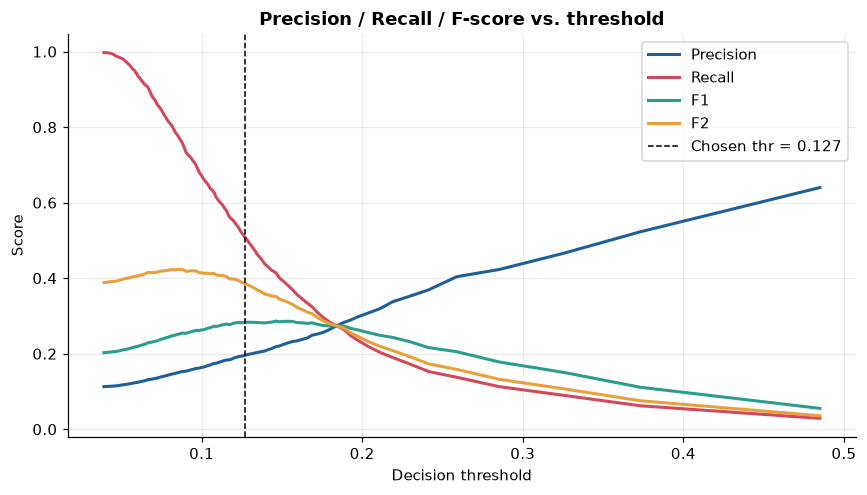

,Threshold,Recall,Precision,Specificity,F1,F2,Flagged %,TP,FP,FN,TN
Operating point,,,,,,,,,,,
Default 0.5,0.500,0.024,0.624,0.998,0.046,0.030,0.429,53,32,2163,17554
"Validation-selected, max F1 (FINAL)",0.127,0.508,0.197,0.739,0.284,0.386,28.841,1125,4586,1091,13000
Recall >= 60%,0.112,0.600,0.179,0.652,0.275,0.408,37.607,1330,6117,886,11469
Recall >= 70%,0.096,0.700,0.161,0.540,0.262,0.420,48.652,1552,8082,664,9504
Recall >= 80%,0.082,0.800,0.146,0.413,0.248,0.423,61.120,1773,10330,443,7256
"Test-optimal F1 (oracle, optimistic)",0.155,0.378,0.231,0.841,0.287,0.335,18.316,838,2789,1378,14797


In [10]:
sweep = ev.threshold_sweep(y, p)
ev.plot_threshold_sweep(sweep, THR, FIG / "04_threshold_sweep.png"); plt.show()

ops = [("Default 0.5", 0.5),
       ("Validation-selected, max F1 (FINAL)", THR),
       ("Recall >= 60%", ev.threshold_for_recall(y, p, 0.60)),
       ("Recall >= 70%", ev.threshold_for_recall(y, p, 0.70)),
       ("Recall >= 80%", ev.threshold_for_recall(y, p, 0.80)),
       ("Test-optimal F1 (oracle, optimistic)", ev.best_f1_threshold(y, p))]
op_tbl = pd.DataFrame([{"Operating point": n, **ev.threshold_metrics(y, p, t)} for n, t in ops])
cols = ["Operating point", "Threshold", "Recall", "Precision", "Specificity", "F1", "F2", "Flagged %", "TP", "FP", "FN", "TN"]
display(op_tbl[cols].set_index("Operating point").round(3)); op_tbl[cols].to_csv(TAB / "04_operating_points.csv", index=False)

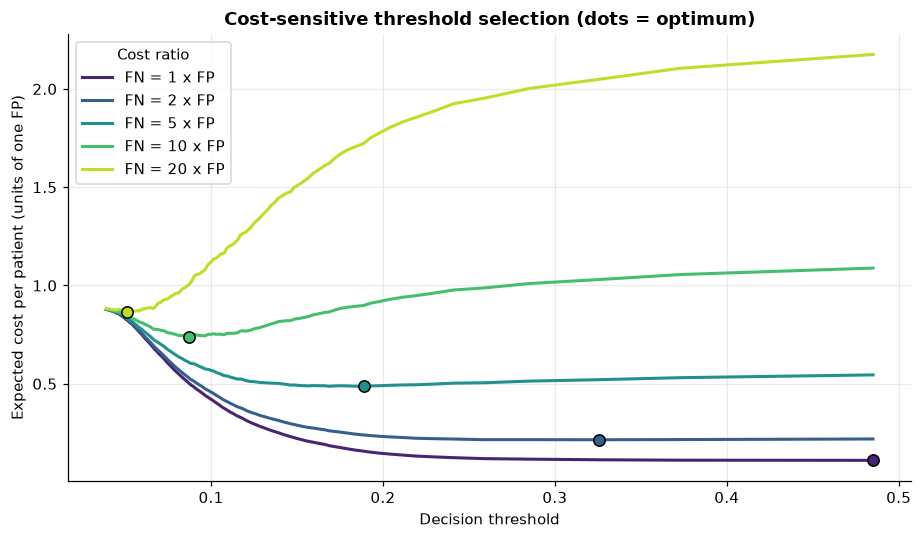

,Bayes thr,Optimal thr,Cost / patient,Treat-none cost,Treat-all cost,Saving vs best trivial %,Recall,Precision,Flagged %
FN:FP cost ratio,,,,,,,,,
1,0.500,0.485,0.110,0.112,0.888,1.264,0.029,0.640,0.505
2,0.333,0.326,0.215,0.224,0.888,3.836,0.090,0.466,2.156
5,0.167,0.189,0.487,0.560,0.888,13.032,0.264,0.283,10.433
10,0.091,0.087,0.740,1.119,0.888,16.689,0.763,0.153,55.959
20,0.048,0.051,0.866,2.238,0.888,2.519,0.981,0.118,93.203


In [11]:
RATIOS = (1, 2, 5, 10, 20)
curves, cs = ev.cost_analysis(y, p, RATIOS)
ev.plot_cost_curves(curves, cs, FIG / "04_cost_curves.png"); plt.show()
display(cs.round(3).set_index("FN:FP cost ratio")); cs.to_csv(TAB / "04_cost_sensitive_optimum.csv", index=False)

*Reading the table.* Cost is expressed in units of one false positive (an unnecessary follow-up call/visit); a false negative costs `k` units.
`Bayes thr = 1/(1+k)` is the theoretically optimal cut-off for perfectly calibrated probabilities; if it lands close to the empirical optimum,
that is further evidence that the model is well calibrated (Section 6).
`Saving vs best trivial` compares to the cheaper of "flag nobody" and "flag everybody": a model only adds value where this is clearly positive.

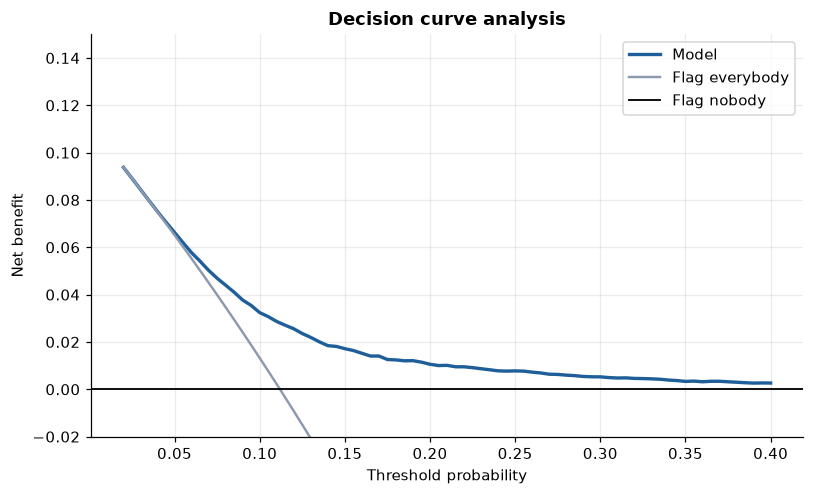

In [12]:
dc = ev.decision_curve(y, p)
ev.plot_decision_curve(dc, FIG / "04_decision_curve.png"); plt.show()
dc.to_csv(TAB / "04_decision_curve.csv", index=False)

## 5. Operational view: who should the hospital call first?

Hospitals can only intervene on a limited number of patients, so rank by predicted risk and look at what the top-k% captures.

,Patients flagged,Readmissions caught,Precision@k,Recall@k,Lift
Top %,,,,,
1,198,111,0.561,0.050,5.010
5,990,357,0.361,0.161,3.222
10,1980,568,0.287,0.256,2.563
20,3960,883,0.223,0.398,1.993
30,5941,1149,0.193,0.519,1.728
50,9901,1575,0.159,0.711,1.421


,n,Readmitted,Observed rate,Mean predicted,Lift,Cum. recall
Decile,,,,,,
1,1981,568,0.287,0.273,2.562,0.256
2,1981,315,0.159,0.168,1.421,0.398
3,1980,267,0.135,0.136,1.205,0.519
4,1980,231,0.117,0.116,1.043,0.623
5,1980,194,0.098,0.101,0.876,0.711
6,1980,176,0.089,0.089,0.794,0.790
7,1980,143,0.072,0.078,0.645,0.855
8,1980,134,0.068,0.069,0.605,0.915
9,1980,113,0.057,0.060,0.510,0.966


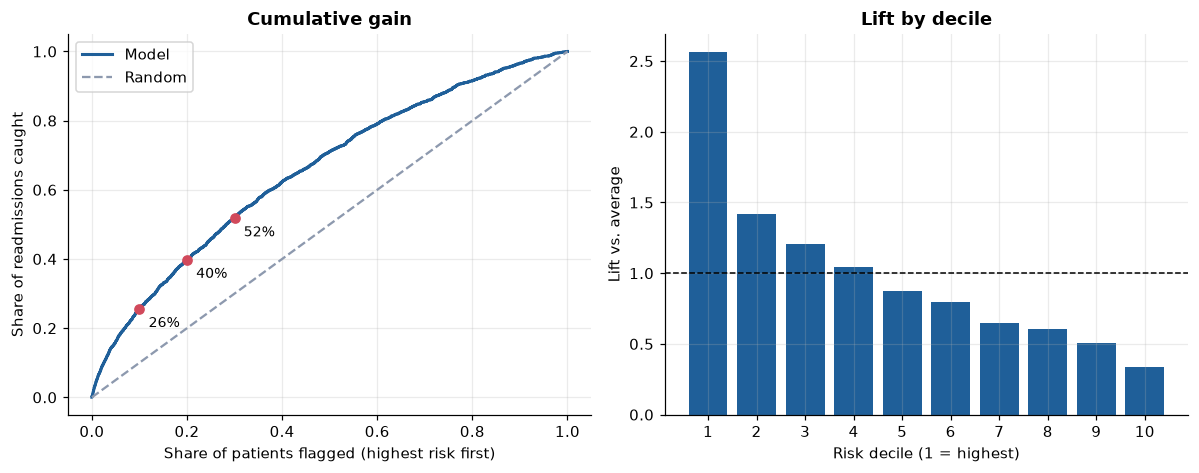

In [13]:
tk = ev.topk_table(y, p); display(tk.round(3).set_index("Top %")); tk.to_csv(TAB / "05_recall_at_topk.csv", index=False)
dt = ev.decile_table(y, p); display(dt.round(3).set_index("Decile")); dt.to_csv(TAB / "05_decile_table.csv", index=False)
ev.plot_gain_lift(y, p, FIG / "05_gain_lift.png"); plt.show()

## 6. Error analysis

Outcome labels at the final threshold: **TP** (caught), **FN** (missed readmission), **FP** (false alarm), **TN**.
Two comparisons answer two different questions:
* **FN vs TP** - why did the model miss some readmissions that look similar to the ones it caught?
* **FP vs TN** - what triggers false alarms?

Numeric features: Cohen's d (effect size) and Mann-Whitney p; categorical features: Cramér's V and chi-square p.
With ~20k rows almost every p-value is tiny, so **rank by effect size, not by p**.

In [14]:
te = add_advanced_features(test.drop(columns="target")).copy()
te["inpatient_bin"] = pd.cut(te["number_inpatient"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
pred_lbl = (p >= THR).astype(int)
out = ev.outcome_labels(y, pred_lbl)
te["outcome"], te["proba"], te["y"] = out, p, y
print(pd.Series(out).value_counts().to_string())

NUM = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
       "number_emergency", "number_inpatient", "number_diagnoses", "total_previous_visits"]
CAT = ["age", "gender", "race", "admission_type_id", "discharge_disposition_id", "admission_source_id", "payer_code",
       "medical_specialty", "diag_1_group", "diag_2_group", "diag_3_group", "insulin", "change", "diabetesMed", "A1Cresult", "max_glu_serum"]
fn_num, fn_cat = ev.compare_groups(te, out == "FN", out == "TP", NUM, CAT, "FN", "TP")
fp_num, fp_cat = ev.compare_groups(te, out == "FP", out == "TN", NUM, CAT, "FP", "TN")
print("\n=== Missed (FN) vs caught (TP) readmissions - numeric ==="); display(fn_num.round(3))
print("=== Missed (FN) vs caught (TP) - categorical (top 8 by Cramér V) ==="); display(fn_cat.head(8).round(3))
print("=== False alarms (FP) vs correct negatives (TN) - numeric ==="); display(fp_num.round(3))
print("=== False alarms (FP) vs correct negatives (TN) - categorical (top 8) ==="); display(fp_cat.head(8).round(3))
for n, d in [("06_fn_vs_tp_numeric", fn_num), ("06_fn_vs_tp_categorical", fn_cat), ("06_fp_vs_tn_numeric", fp_num), ("06_fp_vs_tn_categorical", fp_cat)]:
    d.to_csv(TAB / f"{n}.csv", index=False)

TN    13000
FP     4586
TP     1125
FN     1091

=== Missed (FN) vs caught (TP) readmissions - numeric ===


,Feature,Mean FN,Mean TP,Cohen d,p (Mann-Whitney)
0,number_inpatient,0.166,2.284,-1.166,0.000
1,total_previous_visits,0.562,3.469,-0.937,0.000
2,number_emergency,0.084,0.652,-0.412,0.000
3,num_medications,15.602,17.851,-0.310,0.000
4,time_in_hospital,4.368,5.196,-0.274,0.000
5,number_diagnoses,7.502,7.890,-0.227,0.000
6,num_procedures,1.544,1.207,0.201,0.002
7,number_outpatient,0.312,0.533,-0.167,0.000
8,num_lab_procedures,42.910,44.963,-0.105,0.010


=== Missed (FN) vs caught (TP) - categorical (top 8 by Cramér V) ===


,Feature,Cramér V,p (chi2),Most different level,% FN,% TP
0,discharge_disposition_id,0.388,0.000,1,64.161,33.867
1,medical_specialty,0.204,0.000,Unknown,52.337,47.911
2,diag_1_group,0.191,0.000,Circulatory,33.914,28.533
3,insulin,0.152,0.000,No,47.388,35.911
4,age,0.148,0.000,[60-70),22.915,19.022
5,admission_source_id,0.132,0.000,7,54.537,62.756
6,diag_2_group,0.130,0.007,Circulatory,34.739,28.356
7,payer_code,0.128,0.001,Unknown,39.780,42.933


=== False alarms (FP) vs correct negatives (TN) - numeric ===


,Feature,Mean FP,Mean TN,Cohen d,p (Mann-Whitney)
0,number_inpatient,1.716,0.141,1.724,0.0
1,total_previous_visits,2.753,0.501,1.143,0.0
2,number_diagnoses,8.052,7.138,0.482,0.0
3,number_emergency,0.446,0.080,0.457,0.0
4,time_in_hospital,5.254,4.003,0.429,0.0
5,num_medications,17.625,14.939,0.371,0.0
6,num_lab_procedures,46.107,41.481,0.236,0.0
7,number_outpatient,0.591,0.280,0.233,0.0
8,num_procedures,1.169,1.408,-0.139,0.0


=== False alarms (FP) vs correct negatives (TN) - categorical (top 8) ===


,Feature,Cramér V,p (chi2),Most different level,% FP,% TN
0,discharge_disposition_id,0.406,0.0,1,35.303,71.769
1,insulin,0.161,0.0,No,37.571,51.615
2,age,0.149,0.0,[80-90),22.460,14.362
3,diag_3_group,0.146,0.0,Diabetes,13.585,18.531
4,medical_specialty,0.146,0.0,Cardiology,2.072,6.377
5,diag_2_group,0.128,0.0,Diabetes,9.355,14.077
6,payer_code,0.118,0.0,MC,36.742,29.777
7,admission_source_id,0.114,0.0,7,62.713,53.708


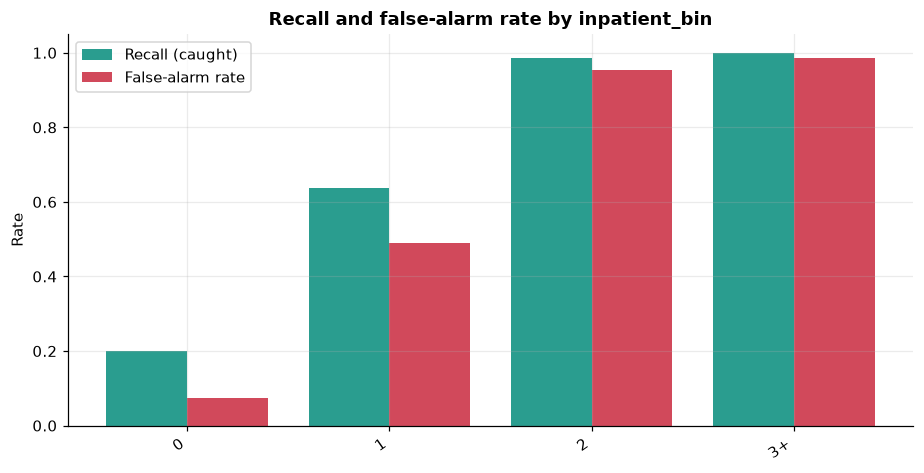

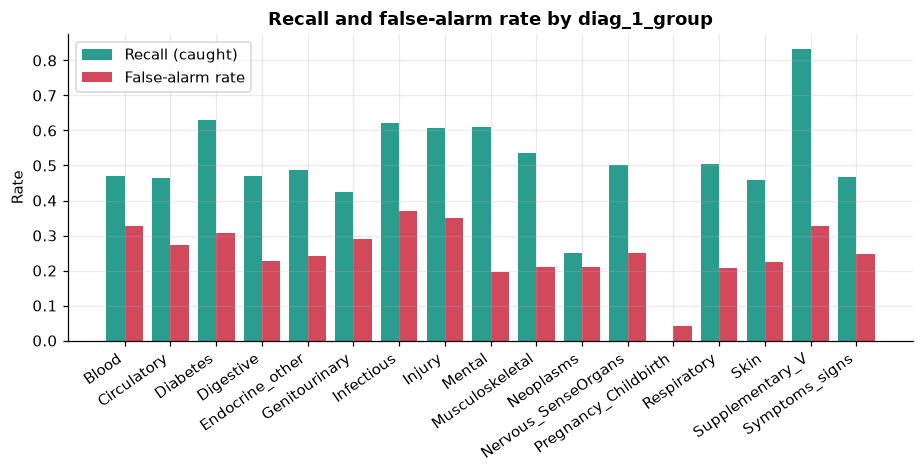

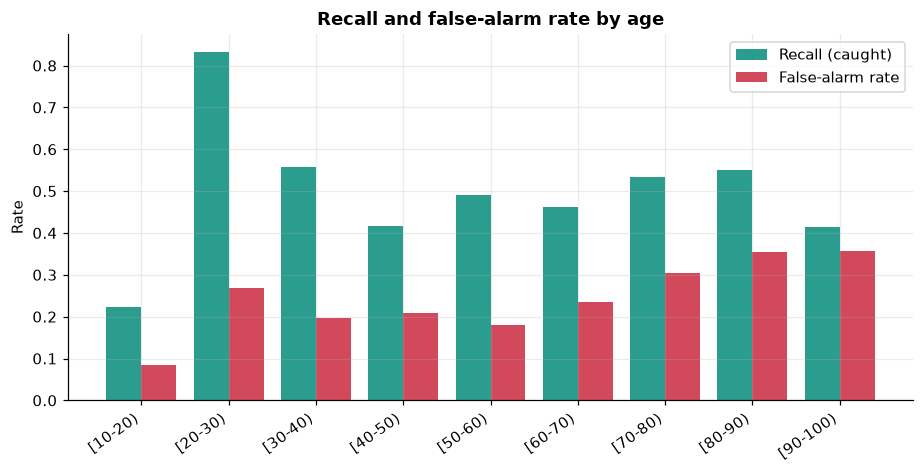

In [15]:
order_age = sorted(te["age"].unique())
ev.plot_error_rate_by(te, y, pred_lbl, "inpatient_bin", ["0", "1", "2", "3+"], FIG / "06_error_by_prior_inpatient.png"); plt.show()
ev.plot_error_rate_by(te, y, pred_lbl, "diag_1_group", None, FIG / "06_error_by_diag1.png"); plt.show()
ev.plot_error_rate_by(te, y, pred_lbl, "age", order_age, FIG / "06_error_by_age.png"); plt.show()

In [16]:
# Most confident mistakes (useful as concrete examples / for SHAP local explanations by Person 2)
cols_show = ["proba", "age", "gender", "time_in_hospital", "number_inpatient", "number_emergency", "num_medications", "discharge_disposition_id", "diag_1_group"]
print("Missed readmissions the model was MOST sure were safe (lowest score among FN):"); display(te[te.outcome == "FN"].nsmallest(5, "proba")[cols_show].round(3))
print("False alarms the model was MOST sure about (highest score among FP):"); display(te[te.outcome == "FP"].nlargest(5, "proba")[cols_show].round(3))

Missed readmissions the model was MOST sure were safe (lowest score among FN):


,proba,age,gender,time_in_hospital,number_inpatient,number_emergency,num_medications,discharge_disposition_id,diag_1_group
13947,0.032,[10-20),Female,3,0,0,1,1,Diabetes
16051,0.034,[50-60),Male,1,0,0,9,1,Musculoskeletal
6858,0.037,[50-60),Male,1,0,0,1,1,Digestive
7258,0.039,[50-60),Male,1,0,0,19,1,Circulatory
865,0.039,[50-60),Female,2,0,0,10,1,Circulatory


False alarms the model was MOST sure about (highest score among FP):


,proba,age,gender,time_in_hospital,number_inpatient,number_emergency,num_medications,discharge_disposition_id,diag_1_group
19463,0.763,[20-30),Female,2,12,3,9,1,Diabetes
15479,0.739,[20-30),Female,1,12,5,8,1,Diabetes
10107,0.714,[20-30),Female,1,12,1,7,1,Diabetes
5606,0.710,[20-30),Female,4,16,3,18,1,Diabetes
11741,0.704,[20-30),Female,8,12,2,22,1,Diabetes


## 7. Calibration and subgroup performance

**Calibration** asks whether "20% risk" really means 20% of such patients are readmitted. It matters because hospitals will use the
probabilities themselves, not just the ranking. Slope = 1 and intercept = 0 are ideal; slope < 1 means over-confident.

,value
ECE,0.0047
Cal. slope,1.0761
Cal. intercept (fit),0.1268
Mean predicted,0.1137
Observed rate,0.1119
Offset (logit),-0.0184


,n,mean_pred,obs_rate,ci_low,ci_high
0,1981,0.0474,0.0379,0.0295,0.0463
1,1980,0.0595,0.0571,0.0469,0.0673
2,1980,0.0686,0.0677,0.0566,0.0787
3,1980,0.0780,0.0727,0.0613,0.0842
4,1980,0.0886,0.0884,0.0759,0.1009
5,1980,0.1013,0.0980,0.0849,0.1111
6,1980,0.1162,0.1172,0.1030,0.1313
7,1980,0.1364,0.1343,0.1193,0.1494
8,1980,0.1680,0.1591,0.1430,0.1752
9,1981,0.2733,0.2867,0.2668,0.3066


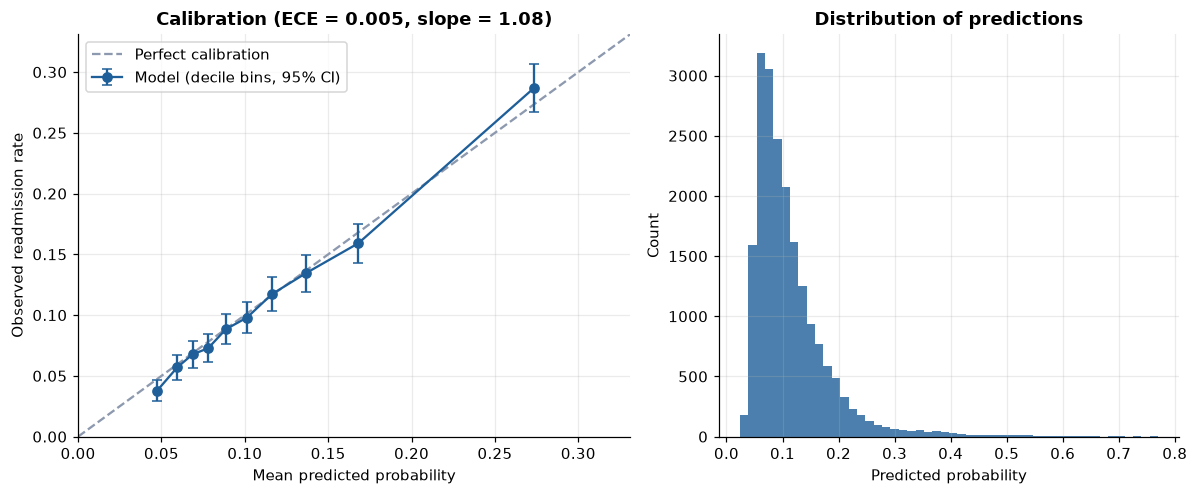

In [17]:
cal = ev.calibration_summary(y, p); display(pd.Series(cal, name="value").round(4).to_frame())
ct = ev.calibration_table(y, p); display(ct.round(4)); ct.to_csv(TAB / "07_calibration_bins.csv", index=False)
pd.Series(cal, name="value").to_csv(TAB / "07_calibration_summary.csv", index_label="metric")
ev.plot_calibration(y, p, path=FIG / "07_calibration.png"); plt.show()

**Subgroups / fairness.** A model with a decent overall AUC can still fail specific groups. Reported per group: ROC-AUC, Recall, false-positive rate,
prevalence. Groups with fewer than 500 rows or 50 positives are listed but flagged `Reliable = False` and excluded from the plots and the gap summary
(their AUCs are too noisy to interpret). Intervals: DeLong for AUC, Wilson for Recall and prevalence.
**Note** that Recall / false-positive differences between groups partly reflect different base rates under one global threshold; they flag where to look, they are not proof of unfair treatment.

,Gap ROC-AUC,Gap Recall,Gap FPR
Feature,,,
age,0.208,0.144,0.177
gender,0.009,0.069,0.032
race,0.012,0.004,0.018
admission_type_id,0.025,0.063,0.089
discharge_disposition_id,0.080,0.295,0.375
diag_1_group,0.146,0.380,0.162
inpatient_bin,0.058,0.799,0.915


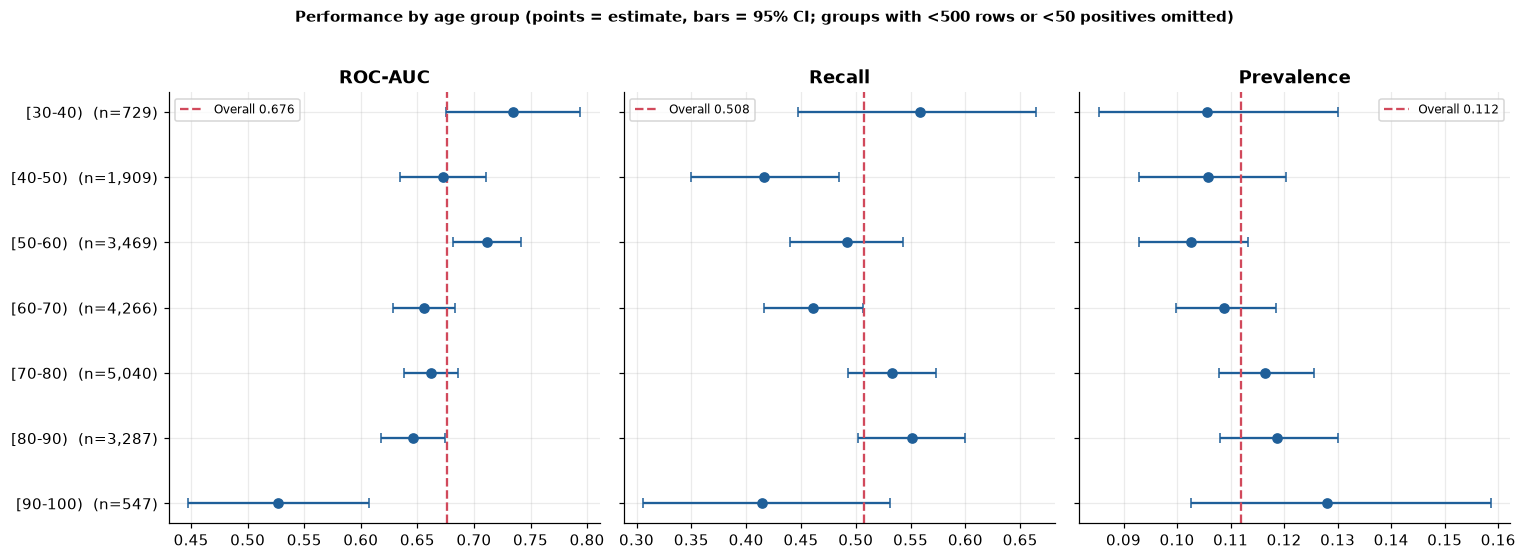

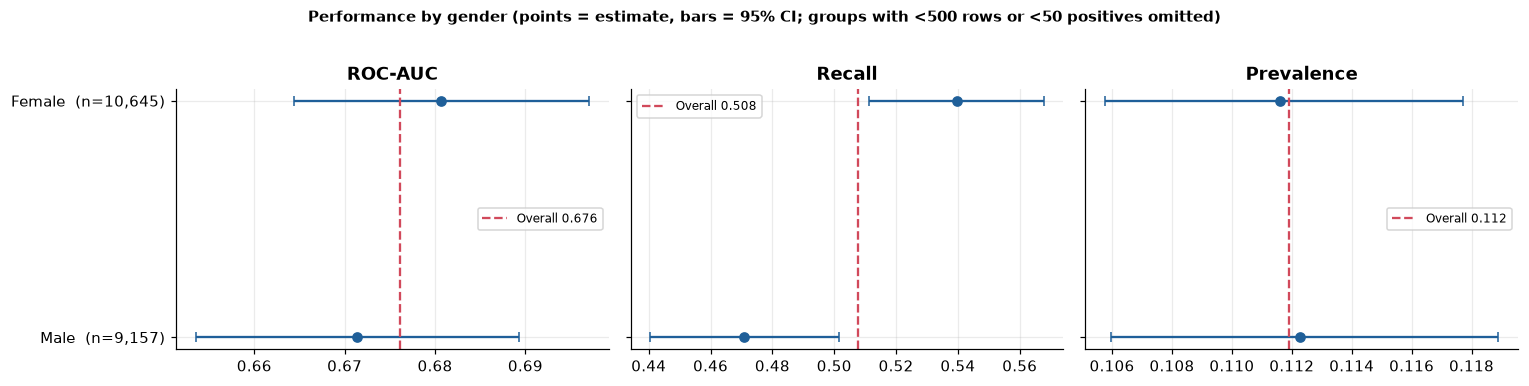

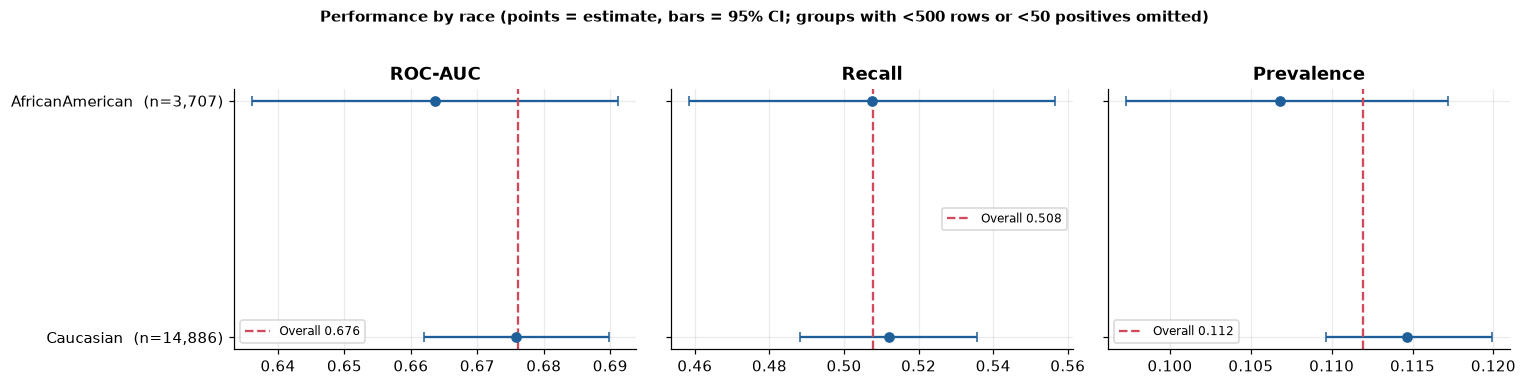

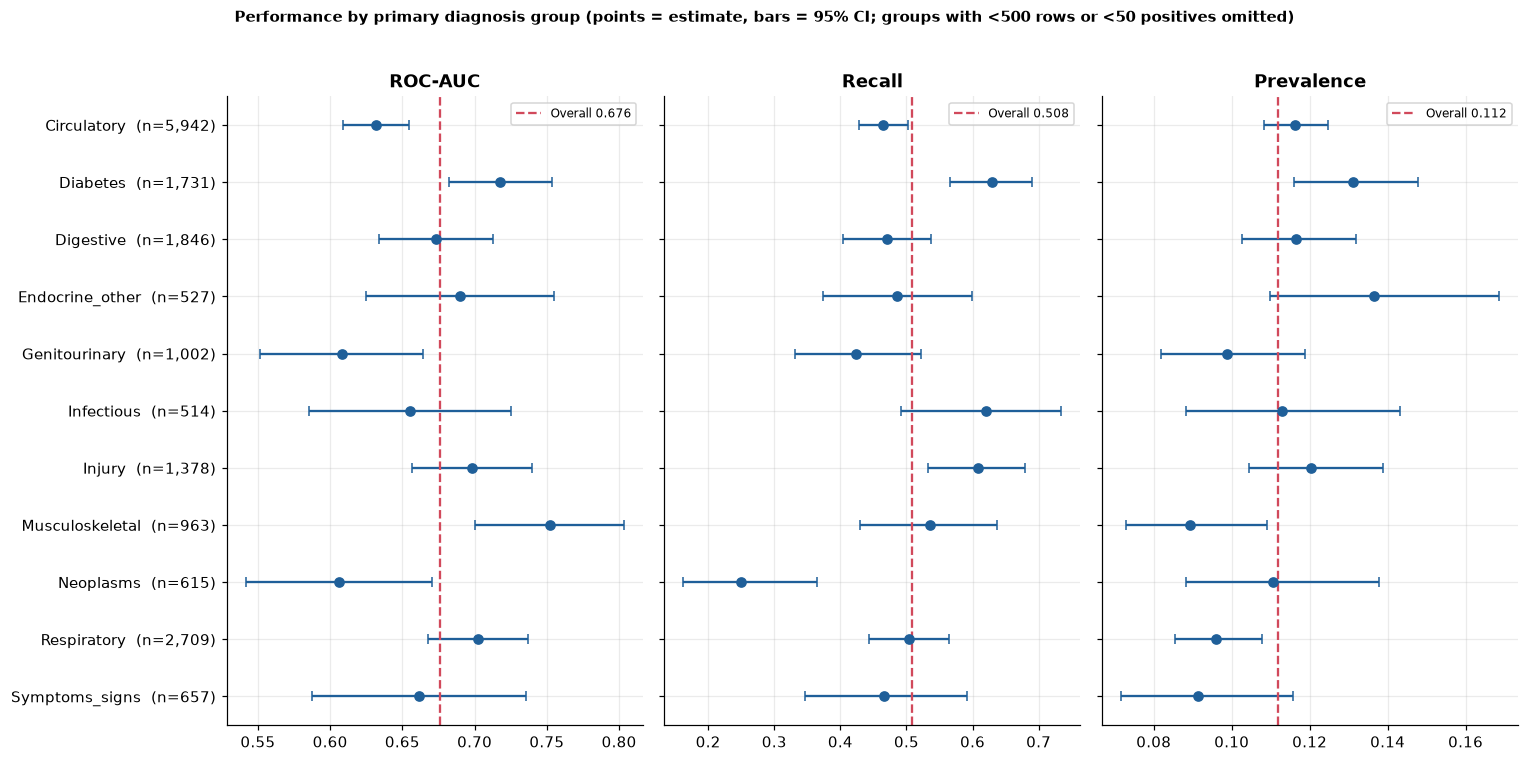

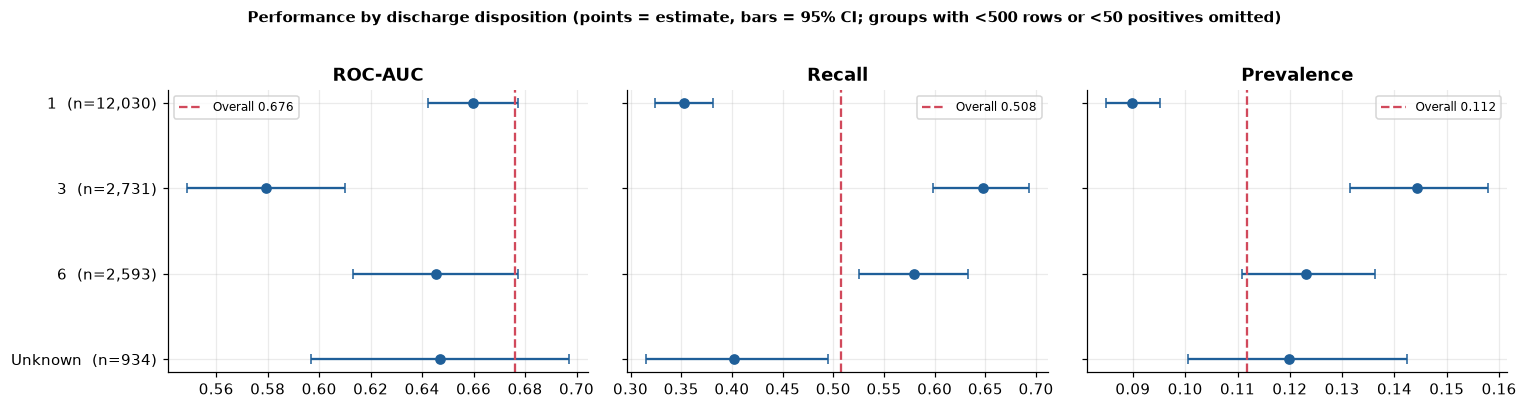

In [18]:
sg_cols = ["age", "gender", "race", "admission_type_id", "discharge_disposition_id", "diag_1_group", "inpatient_bin"]  # reliable = n>=500 and >=50 positives
overall = {"ROC-AUC": auc, "Recall": tm["Recall"], "Prevalence": prev}
reports, gaps = [], []
for c in sg_cols:
    rep = ev.subgroup_report(te, y, p, THR, c); reports.append(rep)
    g = ev.subgroup_gaps(rep); gaps.append({"Feature": c, **{f"Gap {k}": v for k, v in g.items()}})
sg = pd.concat(reports, ignore_index=True)
gap_tbl = pd.DataFrame(gaps)
display(gap_tbl.round(3).set_index("Feature"))
sg.to_csv(TAB / "07_subgroup_performance.csv", index=False); gap_tbl.to_csv(TAB / "07_subgroup_gaps.csv", index=False)
for c, label in [("age", "age group"), ("gender", "gender"), ("race", "race"), ("diag_1_group", "primary diagnosis group"), ("discharge_disposition_id", "discharge disposition")]:
    ev.plot_subgroups(sg[sg.Feature == c], label, overall, FIG / f"07_subgroup_{c}.png"); plt.show()

In [19]:
keep = ["Group", "n", "Positives", "Prevalence", "ROC-AUC", "AUC low", "AUC high", "Recall", "Recall low", "Recall high", "FPR", "Flagged %"]
for f in ["age", "gender", "race", "inpatient_bin"]:
    print(f"--- {f} (reliable groups only)"); display(sg[(sg.Feature == f) & sg.Reliable][keep].round(3).reset_index(drop=True))

--- age (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,[70-80),5040,587,0.116,0.662,0.638,0.686,0.533,0.493,0.573,0.303,33.016
1,[60-70),4266,464,0.109,0.656,0.628,0.683,0.461,0.416,0.507,0.235,25.949
2,[50-60),3469,356,0.103,0.712,0.682,0.742,0.492,0.440,0.543,0.179,21.101
3,[80-90),3287,390,0.119,0.646,0.618,0.674,0.551,0.502,0.600,0.356,37.876
4,[40-50),1909,202,0.106,0.673,0.634,0.711,0.416,0.350,0.485,0.210,23.153
5,[30-40),729,77,0.106,0.735,0.676,0.794,0.558,0.447,0.664,0.196,23.457
6,[90-100),547,70,0.128,0.527,0.447,0.607,0.414,0.306,0.531,0.356,36.380


--- gender (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,Female,10645,1188,0.112,0.681,0.664,0.697,0.540,0.511,0.568,0.276,30.512
1,Male,9157,1028,0.112,0.671,0.653,0.689,0.471,0.440,0.501,0.243,26.897


--- race (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,Caucasian,14886,1707,0.115,0.676,0.662,0.690,0.512,0.488,0.536,0.263,29.135
1,AfricanAmerican,3707,396,0.107,0.664,0.636,0.691,0.508,0.458,0.557,0.281,30.537


--- inpatient_bin (reliable groups only)


,Group,n,Positives,Prevalence,ROC-AUC,AUC low,AUC high,Recall,Recall low,Recall high,FPR,Flagged %
0,0,13277,1142,0.086,0.643,0.626,0.660,0.201,0.178,0.225,0.073,8.383
1,1,3775,484,0.128,0.614,0.587,0.641,0.638,0.595,0.680,0.490,50.861
2,2,1444,236,0.163,0.585,0.545,0.624,0.987,0.963,0.996,0.953,95.845
3,3+,1306,354,0.271,0.640,0.606,0.675,1.000,0.989,1.000,0.987,99.081


## 8. Comparison with public / published baselines

**Important caveat.** The numbers below were taken from the cited pages and are *not* re-run by us. Splits, preprocessing,
class balancing and the definition of the positive class can differ, so they are an orientation, not a controlled head-to-head.
The only controlled comparison is Section 3 (same split, same rows). **Before submitting, open each source and fill in the `Split by patient?` column,**
and replace/add the Kaggle notebooks your instructor expects (edit the list below - the rest updates automatically).

In [22]:
mine = ev.ranking_metrics(y, p)
baselines = pd.DataFrame([
    # source, model, ROC-AUC, AP, note  (None = not reported)
    ("Emi-Johnson & Nkrumah 2025 (Cureus)", "XGBoost",                       0.667, None, "paper; check split"),
    ("Emi-Johnson & Nkrumah 2025 (Cureus)", "Logistic Regression",           0.642, None, "paper; check split"),
    ("Emi-Johnson & Nkrumah 2025 (Cureus)", "Random Forest",                 0.630, None, "paper; check split"),
    ("GitHub: chaitra-satheesh",            "LogReg + RandomOverSampler",    0.649, 0.209, "repo README; check split"),
    ("GitHub: brunoarine/diabetes",         "Random Forest",                 0.66,  None, "repo README; check split"),
    ("GitHub: brunoarine/diabetes",         "Logistic Regression",           0.64,  None, "repo README; check split"),
    ("GitHub: avithekkc",                   "Random Forest (recall-focused)",0.674, None, "repo README; check split"),
], columns=["Source", "Model", "ROC-AUC", "AP", "Note"])
baselines["Split by patient?"] = [
    "No",       # Cureus - stratified split, no patient grouping reported
    "No",
    "No",
    "VERIFY",   # chaitra-satheesh - not verified yet
    "Yes",      # Bruno Arine - duplicate patient_nbr removed first
    "Yes",
    "VERIFY",   # avithekkc - not verified yet
]
ours = pd.DataFrame([{"Source": "This work (patient-grouped split)", "Model": "Tuned CatBoost", "ROC-AUC": mine["ROC-AUC"],
                      "AP": mine["AP (PR-AUC)"], "Note": f"95% CI AUC [{lo:.3f}, {hi:.3f}]", "Split by patient?": "Yes"}])
bl = pd.concat([baselines, ours], ignore_index=True)
display(bl.round(3)); bl.to_csv(TAB / "08_external_baselines.csv", index=False)

,Source,Model,ROC-AUC,AP,Note,Split by patient?
0,Emi-Johnson & Nkrumah 2025 (Cureus),XGBoost,0.667,NaN,paper; check split,No
1,Emi-Johnson & Nkrumah 2025 (Cureus),Logistic Regression,0.642,NaN,paper; check split,No
2,Emi-Johnson & Nkrumah 2025 (Cureus),Random Forest,0.630,NaN,paper; check split,No
3,GitHub: chaitra-satheesh,LogReg + RandomOverSampler,0.649,0.209,repo README; check split,VERIFY
4,GitHub: brunoarine/diabetes,Random Forest,0.660,NaN,repo README; check split,Yes
5,GitHub: brunoarine/diabetes,Logistic Regression,0.640,NaN,repo README; check split,Yes
6,GitHub: avithekkc,Random Forest (recall-focused),0.674,NaN,repo README; check split,VERIFY
7,This work (patient-grouped split),Tuned CatBoost,0.676,0.243,"95% CI AUC [0.664, 0.688]",Yes


## 9. Key numbers for the report (auto-generated)

In [21]:
k5 = cs[cs["FN:FP cost ratio"] == 5].iloc[0]; k10 = cs[cs["FN:FP cost ratio"] == 10].iloc[0]
t10 = tk[tk["Top %"] == 10].iloc[0]; t20 = tk[tk["Top %"] == 20].iloc[0]
lines = [
 f"ROC-AUC {auc:.3f} (95% CI {lo:.3f}-{hi:.3f}); AP {r['AP (PR-AUC)']:.3f} = {r['AP / prevalence']:.2f}x the random baseline of {prev:.3f}.",
 f"At the validation-selected threshold {THR:.3f}: Recall {tm['Recall']:.3f}, Precision {tm['Precision']:.3f}, F1 {tm['F1']:.3f}; {tm['Flagged %']:.1f}% of patients flagged.",
 f"Top 10% highest-risk patients: {t10['Precision@k']:.1%} are readmitted (lift {t10['Lift']:.2f}) and capture {t10['Recall@k']:.1%} of all readmissions; top 20% capture {t20['Recall@k']:.1%}.",
 f"Calibration: ECE {cal['ECE']:.3f}, slope {cal['Cal. slope']:.2f}.",
 f"Cost-sensitive: with FN = 5xFP the optimal threshold is {k5['Optimal thr']:.3f} (saving {k5['Saving vs best trivial %']:.1f}% vs best trivial policy); with FN = 10xFP it is {k10['Optimal thr']:.3f} (saving {k10['Saving vs best trivial %']:.1f}%).",
]
display(Markdown("\n".join("- " + l for l in lines)))
(TAB / "09_key_numbers.txt").write_text("\n".join(lines))

- ROC-AUC 0.676 (95% CI 0.664-0.688); AP 0.243 = 2.17x the random baseline of 0.112.
- At the validation-selected threshold 0.127: Recall 0.508, Precision 0.197, F1 0.284; 28.8% of patients flagged.
- Top 10% highest-risk patients: 28.7% are readmitted (lift 2.56) and capture 25.6% of all readmissions; top 20% capture 39.8%.
- Calibration: ECE 0.005, slope 1.08.
- Cost-sensitive: with FN = 5xFP the optimal threshold is 0.189 (saving 13.0% vs best trivial policy); with FN = 10xFP it is 0.087 (saving 16.7%).

501